# Environment check: Python modules + Quantum ESPRESSO

Run all cells (kernel **Python (qe_exp)**). Each check records PASS/FAIL; the last cell prints a summary.

1. Checking loading of all python modules
2. Quantum ESPRESSO executables + ASE configuration are wired in
3. Silicon SCF from the [pranabdas hands-on tutorial](https://pranabdas.github.io/espresso/hands-on/scf) runs and reproduces its reference numbers
4. Compare local results with published results
5. Output parses with ASE, pymatgen and qe-tools; SCF convergence is plotted
6. Plot of convergence per scf iteration
7. Checking convergence of wavefunciton cut off, k points in mesh, and cell dm parameters
8. Optimization the structure with SCF
9. Calculating the density of states with NSCF

In [1]:
import sys, os, shutil, subprocess, importlib, re, time, urllib.request
from pathlib import Path

CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f" - {detail}" if detail else ""))

ROOT = Path.cwd()
print("Project root:", ROOT)
check(".venv interpreter", Path(sys.prefix).resolve() == (ROOT / ".venv").resolve(), sys.executable)
check("Python >= 3.10", sys.version_info >= (3, 10), sys.version.split()[0])

Project root: C:\Users\Caesium\Desktop\qe_exp
[PASS] .venv interpreter - C:\Users\Caesium\Desktop\qe_exp\.venv\Scripts\python.exe
[PASS] Python >= 3.10 - 3.12.6


## 1. Python modules

In [5]:
MODULES = ["numpy", "scipy", "matplotlib", "pandas", "ase", "ase.calculators.espresso", "ase.io.espresso",
           "pymatgen.core", "pymatgen.io.pwscf", "qe_tools", "seekpath", "spglib",
           "ipykernel", "ipywidgets", "jupyterlab", "notebook"]
rows = []
for m in MODULES:
    try:
        mod = importlib.import_module(m)
        top = sys.modules[m.split(".")[0]]
        rows.append((m, getattr(top, "__version__", "?"), "ok"))
    except Exception as e:
        rows.append((m, "-", f"{type(e).__name__}: {e}"))

import pandas as pd
display(pd.DataFrame(rows, columns=["module", "version", "status"]))
failed = [r[0] for r in rows if r[2] != "ok"]
check("all modules import", not failed, ", ".join(failed) or f"{len(rows)} modules")

,module,version,status
0,numpy,2.5.4,ok
1,scipy,1.18.1,ok
2,matplotlib,3.11.2,ok
3,pandas,3.1.0,ok
4,ase,3.29.0,ok
5,ase.calculators.espresso,3.29.0,ok
6,ase.io.espresso,3.29.0,ok
7,pymatgen.core,?,ok
8,pymatgen.io.pwscf,?,ok
9,qe_tools,2.3.0,ok


[PASS] all modules import - 16 modules


## 2. Quantum ESPRESSO wiring

In [6]:
from ase.config import cfg

PW = shutil.which("pw.x.exe") or shutil.which("pw.x")
check("pw.x on PATH", PW, PW)
QE_BIN = Path(PW).parent if PW else ROOT / "qe" / "bin"
for exe in ["pw.x", "ph.x", "pp.x", "dos.x", "bands.x", "projwfc.x", "q2r.x", "matdyn.x"]:
    check(f"{exe} present", (QE_BIN / f"{exe}.exe").exists() or (QE_BIN / exe).exists())

for var in ["ASE_CONFIG_PATH", "ESPRESSO_PSEUDO", "OMP_STACKSIZE"]:
    check(f"env {var}", os.environ.get(var), os.environ.get(var))

esp = dict(cfg.parser["espresso"]) if cfg.parser.has_section("espresso") else {}
check("ASE [espresso] config", esp.get("command") and Path(esp["command"]).exists(), str(esp))

[PASS] pw.x on PATH - C:\Users\Caesium\Desktop\qe_exp\qe\bin\pw.x.exe
[PASS] pw.x present
[PASS] ph.x present
[PASS] pp.x present
[PASS] dos.x present
[PASS] bands.x present
[PASS] projwfc.x present
[PASS] q2r.x present
[PASS] matdyn.x present
[PASS] env ASE_CONFIG_PATH - C:\Users\Caesium\Desktop\qe_exp\ase.ini
[PASS] env ESPRESSO_PSEUDO - C:\Users\Caesium\Desktop\qe_exp\pseudo
[PASS] env OMP_STACKSIZE - 256M
[PASS] ASE [espresso] config - {'command': 'C:/Users/Caesium/Desktop/qe_exp/qe/bin/pw.x.exe', 'pseudo_dir': 'C:/Users/Caesium/Desktop/qe_exp/pseudo'}


## 3. Silicon SCF (tutorial input)

Pseudopotential `Si.pz-vbc.UPF` is fetched from the QE pseudopotential library if it isn't already in the project's `pseudo/` folder.
The input below is the tutorial's, with `pseudo_dir`/`outdir` pointed at this project.

In [8]:
# Setting up the directories and data for the calculation
PSEUDO_DIR = ROOT / "pseudo"
PSEUDO_DIR.mkdir(exist_ok=True)
upf = PSEUDO_DIR / "Si.pz-vbc.UPF"
if not upf.exists():
    urllib.request.urlretrieve("https://pseudopotentials.quantum-espresso.org/upf_files/Si.pz-vbc.UPF", upf)
check("Si.pz-vbc.UPF available", upf.exists() and "PP_HEADER" in upf.read_text(errors="ignore"), str(upf))

RUN = ROOT / "runs" / "scf_silicon"
RUN.mkdir(parents=True, exist_ok=True)

# Write the input for the calculation
INPUT = f'''&CONTROL
  calculation = 'scf'
  prefix = 'silicon'
  outdir = './tmp/'
  pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
  verbosity = 'high'
/
&SYSTEM
  ibrav = 2
  celldm(1) = 10.26
  nat = 2
  ntyp = 1
  ecutwfc = 30
  nbnd = 8
/
&ELECTRONS
  mixing_beta = 0.6
/
ATOMIC_SPECIES
  Si 28.086 Si.pz-vbc.UPF
ATOMIC_POSITIONS (alat)
  Si 0.00 0.00 0.00
  Si 0.25 0.25 0.25
K_POINTS (automatic)
  6 6 6 0 0 0
'''
(RUN / "pw.scf.silicon.in").write_text(INPUT)

[PASS] Si.pz-vbc.UPF available - C:\Users\Caesium\Desktop\qe_exp\pseudo\Si.pz-vbc.UPF


414

### What this input describes

- **A** Diamond Si is two interpenetrating FCC, `ibrac = 2` `celldm(1)`, sublattices offset by (¼,¼,¼)·a, `ATOMIC_POSITIONS`. Each contributes one atom per primitive cell, hence `nat = 2`.
- **B** maps every hard-coded constant to its meaning.
- **C** shows how the periodic crystal becomes a plane-wave basis. Bloch's theorem means only reciprocal-lattice vectors
  **G** appear in $\psi_{n\mathbf{k}}(\mathbf{r})=\sum_\mathbf{G} c_{n\mathbf{k}}(\mathbf{G})e^{i(\mathbf{k}+\mathbf{G})\cdot\mathbf{r}}$.
  The two cutoffs keep the G inside a sphere: $|\mathbf{k}+\mathbf{G}|^2 \le$ `ecutwfc` for ψ, and
  $|\mathbf{G}|^2 \le$ `ecutrho` $= 4\,$`ecutwfc` for the density ρ = Σ|ψ|², which needs G up to twice as long.
  In Rydberg atomic units ħ²/2m = 1, so a plane wave's kinetic energy is simply |k+G|² in Ry.
- **D** is a 1-D sketch of why a cutoff works: sharp features near the atoms need short-wavelength (high-energy) plane waves.

The plane-wave and G-vector counts are computed from the input constants (k-points from spglib) and match `pw.x`.

The `1067` in `pw.x`'s `Sum` line is *not* the per-k basis size. It counts the G-vectors in a sphere of radius
√ecutwfc + |k|max, which QE allocates so that it contains every k-point's set. Each k-point actually uses 725–757 plane waves.

The code is in [si_figure.py](si_figure.py).

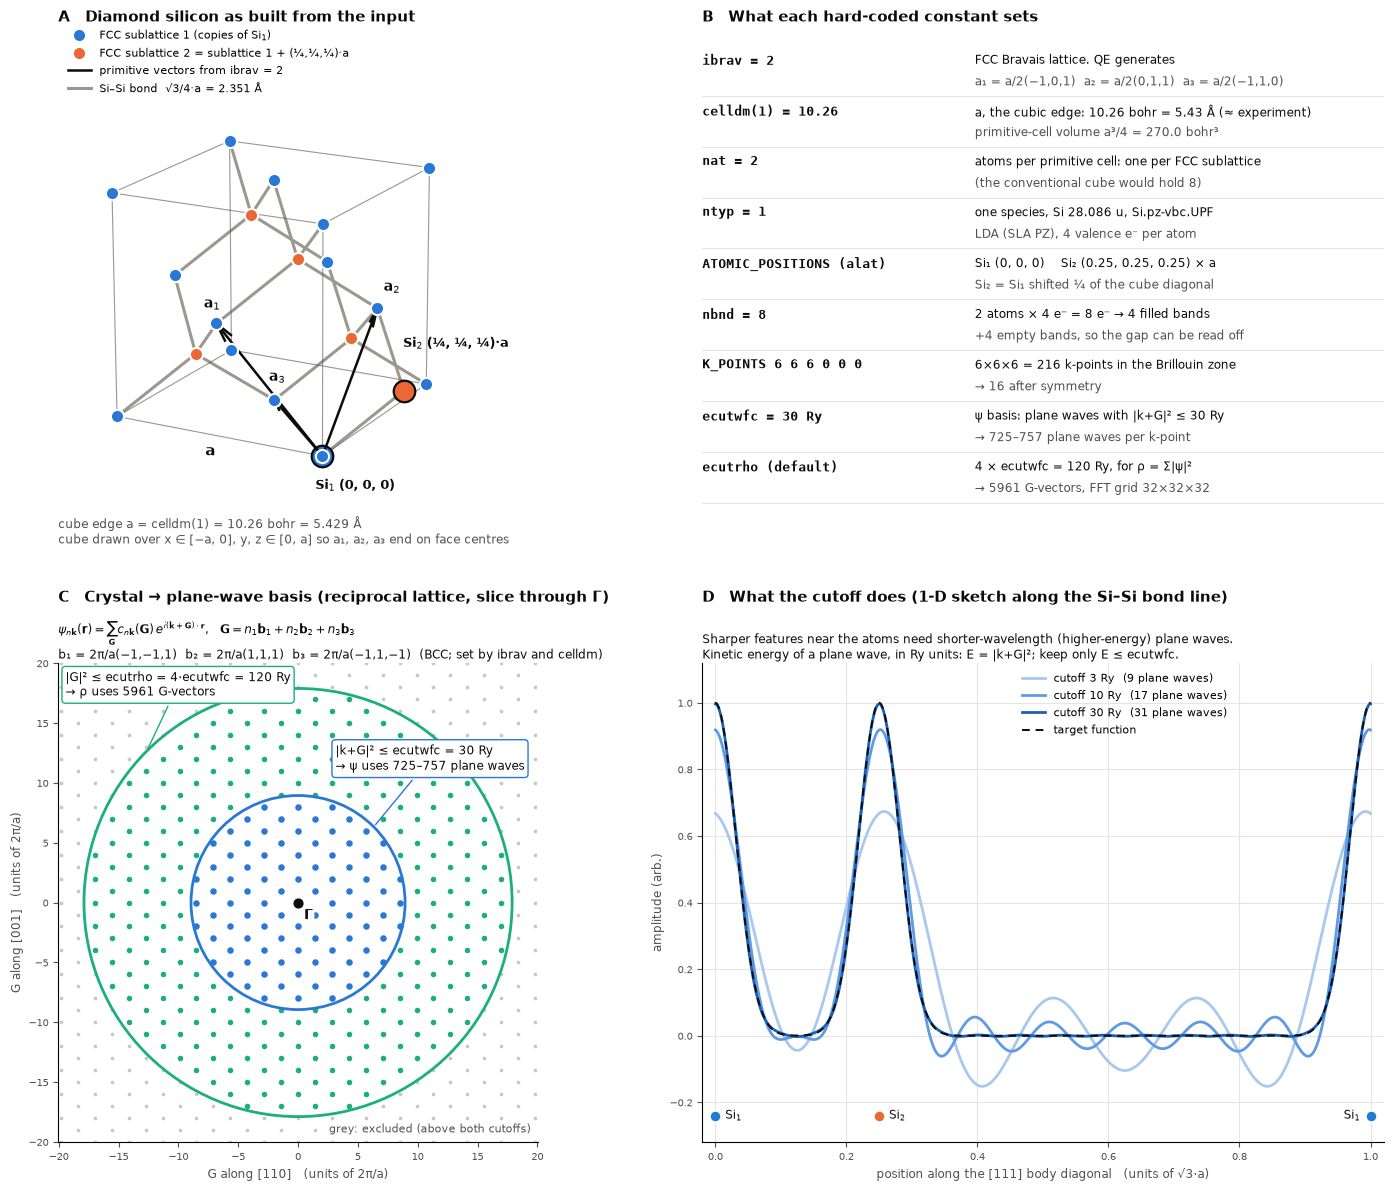

[PASS] plane-wave sets from input constants - 16 k-points, 725-757 PW/k, 5961 G for rho


In [9]:
import matplotlib.pyplot as plt
from si_figure import make_si_figure
fig, pw_counts = make_si_figure(a_bohr=10.26, ecutwfc=30)
plt.show()
check("plane-wave sets from input constants", pw_counts["n_rho"] == 5961 and len(pw_counts["npw_k"]) == 16,
      f"{len(pw_counts['npw_k'])} k-points, {min(pw_counts['npw_k'])}-{max(pw_counts['npw_k'])} PW/k, {pw_counts['n_rho']} G for rho")

In [10]:
# Equivalent of:  pw.x < pw.scf.silicon.in > pw.scf.silicon.out
# Runs the calculation
t0 = time.time()
with open(RUN / "pw.scf.silicon.in") as fin, open(RUN / "pw.scf.silicon.out", "w") as fout:
    proc = subprocess.run([PW], stdin=fin, stdout=fout, stderr=subprocess.PIPE, cwd=RUN, text=True)
elapsed = time.time() - t0
OUT = (RUN / "pw.scf.silicon.out").read_text()

check("pw.x exit code 0", proc.returncode == 0, f"code {proc.returncode} {proc.stderr[-300:]}")
check("JOB DONE", "JOB DONE" in OUT, f"{elapsed:.1f} s")
check("SCF converged", "convergence has been achieved" in OUT)
print(re.search(r"Program PWSCF.*", OUT).group(0))

[PASS] pw.x exit code 0 - code 0 Note: The following floating-point exceptions are signalling: IEEE_UNDERFLOW_FLAG IEEE_DENORMAL

[PASS] JOB DONE - 7.9 s
[PASS] SCF converged
Program PWSCF v.7.6 starts on  4Nov2026 at 23:30: 8 


## 4. Compare with the tutorial's reference values

The basis set (1067 plane waves, FFT grid) and XC functional must match the tutorial **exactly**.
Energies and band edges are compared with a looser tolerance: the `Si.pz-vbc.UPF` currently served by the QE
library (MD5 `9f25e6ff…`) is a newer revision than the file used for the tutorial (and the 2017 QE test-suite),
which shifts the total energy by ~2 mRy and the absolute band edges by ~0.15 eV. The strict test of the build
itself is section 5, against QE's official regression benchmark.

In [11]:
total = [float(x) for x in re.findall(r"^\s*total energy\s+=\s+(-?\d+\.\d+) Ry", OUT, re.M)]
final = float(re.search(r"^!\s+total energy\s+=\s+(-?\d+\.\d+) Ry", OUT, re.M).group(1))
acc = [float(x) for x in re.findall(r"estimated scf accuracy\s+<\s+([\d.Ee+-]+) Ry", OUT)]
homo, lumo = map(float, re.search(r"highest occupied, lowest unoccupied level \(ev\):\s+(\S+)\s+(\S+)", OUT).groups())
npw = int(re.search(r"Sum\s+\d+\s+\d+\s+\d+\s+\d+\s+\d+\s+(\d+)", OUT).group(1)) if re.search(r"Sum\s+\d+", OUT) else None
xc = re.search(r"Exchange-correlation=\s*(.*)", OUT).group(1).strip()

#        quantity              tutorial      this run     tolerance
REF = {"plane waves":         (1067,         npw,         0),
       "final energy (Ry)":   (-15.85219789, final,       5e-3),
       "HOMO (eV)":           (6.2117,       homo,        0.25),
       "LUMO (eV)":           (6.8442,       lumo,        0.25),
       "band gap (eV)":       (0.6325,       lumo - homo, 0.05),
       "SCF iterations":      (4,            len(acc),    1)}
cmp = pd.DataFrame([(k, r, v, v - r, tol, abs(v - r) <= tol) for k, (r, v, tol) in REF.items()],
                   columns=["quantity", "tutorial", "this run", "difference", "tolerance", "match"])
check("XC functional is LDA (SLA PZ)", xc.split()[:2] == ["SLA", "PZ"], xc)
display(cmp)
print("XC functional:", xc)
for k, (r, v, tol) in REF.items():
    check(f"{k} matches tutorial", abs(v - r) <= tol, f"{v:.6g} vs {r:.6g}")

[PASS] XC functional is LDA (SLA PZ) - SLA  PZ   NOGX NOGC


,quantity,tutorial,this run,difference,tolerance,match
0,plane waves,1067.000000,1067.000000,0.000000,0.000,True
1,final energy (Ry),-15.852198,-15.850394,0.001804,0.005,True
2,HOMO (eV),6.211700,6.052300,-0.159400,0.250,True
3,LUMO (eV),6.844200,6.711300,-0.132900,0.250,True
4,band gap (eV),0.632500,0.659000,0.026500,0.050,True
5,SCF iterations,4.000000,4.000000,0.000000,1.000,True


XC functional: SLA  PZ   NOGX NOGC
[PASS] plane waves matches tutorial - 1067 vs 1067
[PASS] final energy (Ry) matches tutorial - -15.8504 vs -15.8522
[PASS] HOMO (eV) matches tutorial - 6.0523 vs 6.2117
[PASS] LUMO (eV) matches tutorial - 6.7113 vs 6.8442
[PASS] band gap (eV) matches tutorial - 0.659 vs 0.6325
[PASS] SCF iterations matches tutorial - 4 vs 4


## 5. Official QE regression benchmark (strict build check)

Runs `test-suite/pw_scf` inputs from the QE 7.6 source folder with this `pw.x` and compares the final energy with
the developers' benchmark outputs to 1e-5 Ry. Skipped if the source folder is not present.

In [13]:
import tempfile
TS = ROOT / "q-e-qe-7.6" / "test-suite" / "pw_scf"
FINAL_RE = re.compile(r"^!\s+total energy\s+=\s+(-?\d+\.\d+)", re.M)
if TS.exists():
    rows = []
    for name in ["scf.in", "scf-kauto.in", "scf-mixing_beta.in", "scf-k0.in"]:
        txt = (TS / name).read_text()
        work = Path(tempfile.mkdtemp())
        txt = re.sub(r"pseudo_dir\s*=\s*'[^']*'", "", txt, flags=re.I)
        txt = re.sub(r"&control", f"&control\n  pseudo_dir='{PSEUDO_DIR.as_posix()}', outdir='{work.as_posix()}',",
                     txt, count=1, flags=re.I)
        out = subprocess.run([PW], input=txt, capture_output=True, text=True, cwd=work).stdout
        shutil.rmtree(work, ignore_errors=True)
        ours = FINAL_RE.findall(out)
        ref = FINAL_RE.findall((TS / f"benchmark.out.git.inp={name}").read_text())
        e_ours = float(ours[-1]) if ours else float("nan")
        diff = abs(e_ours - float(ref[-1]))
        rows.append((name, e_ours, float(ref[-1]), diff, diff < 1e-5))
        check(f"benchmark {name}", diff < 1e-5, f"|dE| = {diff:.1e} Ry")
    display(pd.DataFrame(rows, columns=["test", "this build (Ry)", "QE benchmark (Ry)", "|dE| (Ry)", "match"]))
else:
    print("q-e-qe-7.6 source folder not found - benchmark skipped")

[PASS] benchmark scf.in - |dE| = 1.5e-06 Ry
[PASS] benchmark scf-kauto.in - |dE| = 1.4e-06 Ry
[PASS] benchmark scf-mixing_beta.in - |dE| = 3.7e-07 Ry
[PASS] benchmark scf-k0.in - |dE| = 1.7e-06 Ry


,test,this build (Ry),QE benchmark (Ry),|dE| (Ry),match
0,scf.in,-15.794494,-15.794496,1.460000e-06,True
1,scf-kauto.in,-15.794495,-15.794496,1.410000e-06,True
2,scf-mixing_beta.in,-15.794496,-15.794496,3.700000e-07,True
3,scf-k0.in,-14.518758,-14.518760,1.660000e-06,True


## 6. Parse the output with the Python QE tools

In [14]:
from ase.io import read
from ase.units import Ry
atoms = read(RUN / "pw.scf.silicon.out", format="espresso-out")
e_ase = atoms.get_potential_energy()
check("ASE reads output", abs(e_ase - final * Ry) < 1e-4, f"{e_ase:.6f} eV = {e_ase / Ry:.8f} Ry, {len(atoms)} atoms")

from pymatgen.io.pwscf import PWInput, PWOutput
pmo = PWOutput(str(RUN / "pw.scf.silicon.out"))
check("pymatgen PWOutput", abs(pmo.final_energy - final) < 1e-6, f"{pmo.final_energy:.8f} Ry")  # pymatgen reports Ry

from qe_tools.parsers import PwInputFile
pin = PwInputFile(INPUT)
check("qe-tools parses input", len(pin.structure["positions"]) == 2, f"species {pin.atomic_species['names']}")

[PASS] ASE reads output - -215.655581 eV = -15.85039296 Ry, 2 atoms
[PASS] pymatgen PWOutput - -15.85039422 Ry
[PASS] qe-tools parses input - species ['Si']


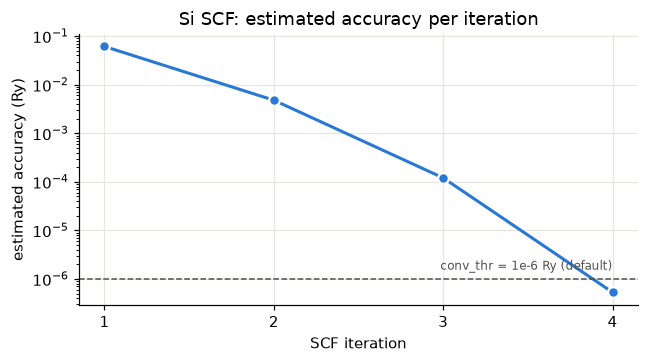

In [15]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3.4), dpi=110)
ax.semilogy(range(1, len(acc) + 1), acc, color="#2a78d6", lw=2, marker="o", ms=7, markeredgecolor="white", markeredgewidth=1.5)
ax.axhline(1e-6, color="#52514e", lw=1, ls="--")
ax.annotate("conv_thr = 1e-6 Ry (default)", (len(acc), 1e-6), xytext=(0, 6), textcoords="offset points", ha="right", fontsize=8, color="#52514e")
ax.set(title="Si SCF: estimated accuracy per iteration", xlabel="SCF iteration", ylabel="estimated accuracy (Ry)")
ax.set_xticks(range(1, len(acc) + 1))
ax.grid(True, which="major", color="#e6e5e0", lw=0.8)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## 7. Convergence tests ([pranabdas tutorial](https://pranabdas.github.io/espresso/hands-on/convergence))

These are the tutorial's three scans, run from Python in place of its PWTK and `/bin/sh` scripts:

| test | varied | fixed |
|---|---|---|
| 7a cutoff | `ecutwfc` = 10…40 Ry (the shell-script list 10, 15, …, 40 plus the PWTK list 12, 16, …, 32) | `celldm(1)` = 10.0, k = 6 6 6 1 1 1 |
| 7b k-points | Monkhorst-Pack k×k×k, shift 1 1 1, k = 2, 4, 6, 8 | `ecutwfc` = 30, `celldm(1)` = 10.0 |
| 7c lattice constant | `celldm(1)` = 9.7…10.7 bohr, step 0.1 | `ecutwfc` = 30, k = 6 6 6 1 1 1 |

The base input is the tutorial's script template (`celldm(1) = 10.0`, shifted 6×6×6 mesh), so absolute energies differ
from section 3. The tutorial gives no numerical results, so the checks use the usual criterion:
**|ΔE| < 1 mRy/atom** from the best-converged point. The lattice scan must give a sensible LDA equilibrium.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
CONV = ROOT / "runs" / "convergence"
CONV.mkdir(parents=True, exist_ok=True)
TEMPLATE = '''&control
    calculation = 'scf',
    prefix = '{prefix}'
    outdir = './tmp/'
    pseudo_dir = '{pseudo}/'
/
&system
    ibrav = 2,
    celldm(1) = {alat},
    nat = 2,
    ntyp = 1,
    ecutwfc = {ecut}
/
&electrons
    mixing_beta = 0.6
/
ATOMIC_SPECIES
Si 28.086 Si.pz-vbc.UPF
ATOMIC_POSITIONS (alat)
Si 0.0 0.0 0.0
Si 0.25 0.25 0.25
K_POINTS (automatic)
{k} {k} {k} 1 1 1
'''
NAT = 2
MRY_PER_ATOM = 1e-3 * NAT          # 1 mRy/atom threshold, expressed per cell (Ry)

def run_pw(test, tag, ecut=30, alat=10.0, k=6):
    # Write <tag>.in, run  pw.x < tag.in > tag.out, grep '!' energy - same as the tutorial's shell loop
    d = CONV / test
    d.mkdir(exist_ok=True)
    inp = TEMPLATE.format(prefix=tag, pseudo=PSEUDO_DIR.as_posix(), alat=alat, ecut=ecut, k=k)
    (d / f"{tag}.in").write_text(inp)
    with open(d / f"{tag}.in") as fin, open(d / f"{tag}.out", "w") as fout:
        rc = subprocess.run([PW], stdin=fin, stdout=fout, stderr=subprocess.DEVNULL, cwd=d).returncode
    shutil.rmtree(d / "tmp", ignore_errors=True)          # wavefunctions are not needed afterwards
    out = (d / f"{tag}.out").read_text()
    m = FINAL_RE.search(out)
    nk = int(re.search(r"number of k points=\s+(\d+)", out).group(1))
    if rc != 0 or not m or "JOB DONE" not in out:
        raise RuntimeError(f"pw.x failed for {test}/{tag} (exit {rc})")
    return float(m.group(1)), nk

### 7a. Plane-wave cutoff `ecutwfc`

In [17]:
ECUTS = sorted(set(range(10, 41, 5)) | set(range(12, 33, 4)))      # shell-script list + PWTK list
t0 = time.time()
ecut_rows = []
for ec in ECUTS:
    e, nk = run_pw("ecut", f"ecut_{ec}", ecut=ec)
    ecut_rows.append((ec, e))
    print(f"ecut_{ec:<3d}  !    total energy  = {e:.8f} Ry")       # what `grep !` prints in the tutorial
print(f"{len(ECUTS)} runs in {time.time() - t0:.0f} s")

ecut_df = pd.DataFrame(ecut_rows, columns=["ecutwfc (Ry)", "E (Ry)"])
ecut_df["E - E(40) (mRy/atom)"] = (ecut_df["E (Ry)"] - ecut_df["E (Ry)"].iloc[-1]) * 1e3 / NAT
display(ecut_df.style.format({"E (Ry)": "{:.8f}", "E - E(40) (mRy/atom)": "{:.3f}"}).hide(axis="index"))

ECUT_CONV = int(ecut_df.loc[ecut_df["E - E(40) (mRy/atom)"].abs() < 1.0, "ecutwfc (Ry)"].min())
dE = np.diff(ecut_df["E (Ry)"].to_numpy())
check("E(ecutwfc) decreases monotonically (variational)", np.all(dE <= 1e-7), f"max step {dE.max():.2e} Ry")
check("ecutwfc = 30 Ry converged to 1 mRy/atom", ECUT_CONV <= 30,
      f"converged from {ECUT_CONV} Ry; E(30)-E(40) = {ecut_df.set_index('ecutwfc (Ry)').loc[30, 'E - E(40) (mRy/atom)']:.3f} mRy/atom")

ecut_10   !    total energy  = -15.76878829 Ry
ecut_12   !    total energy  = -15.80196103 Ry
ecut_15   !    total energy  = -15.83022056 Ry
ecut_16   !    total energy  = -15.83534941 Ry
ecut_20   !    total energy  = -15.84421275 Ry
ecut_24   !    total energy  = -15.84746494 Ry
ecut_25   !    total energy  = -15.84791108 Ry
ecut_28   !    total energy  = -15.84865953 Ry
ecut_30   !    total energy  = -15.84895848 Ry
ecut_32   !    total energy  = -15.84923396 Ry
ecut_35   !    total energy  = -15.84954343 Ry
ecut_40   !    total energy  = -15.84987823 Ry
12 runs in 247 s


ecutwfc (Ry),E (Ry),E - E(40) (mRy/atom)
10,-15.76878829,40.545
12,-15.80196103,23.959
15,-15.83022056,9.829
16,-15.83534941,7.264
20,-15.84421275,2.833
24,-15.84746494,1.207
25,-15.84791108,0.984
28,-15.84865953,0.609
30,-15.84895848,0.460
32,-15.84923396,0.322


[PASS] E(ecutwfc) decreases monotonically (variational) - max step -2.75e-04 Ry
[PASS] ecutwfc = 30 Ry converged to 1 mRy/atom - converged from 25 Ry; E(30)-E(40) = 0.460 mRy/atom


### 7b. k-point mesh

In [18]:
KS = [2, 4, 6, 8]
k_rows = []
for k in KS:
    e, nk = run_pw("kpoints", f"k_{k}", k=k)
    k_rows.append((f"{k}x{k}x{k}", k ** 3, nk, e))
k_df = pd.DataFrame(k_rows, columns=["mesh (shift 1 1 1)", "k-points in full BZ", "irreducible k-points", "E (Ry)"])
k_df["E - E(8) (mRy/atom)"] = (k_df["E (Ry)"] - k_df["E (Ry)"].iloc[-1]) * 1e3 / NAT
display(k_df.style.format({"E (Ry)": "{:.8f}", "E - E(8) (mRy/atom)": "{:.3f}"}).hide(axis="index"))

K_CONV = int(min(k for k, d in zip(KS, k_df["E - E(8) (mRy/atom)"]) if abs(d) < 1.0))
check("6x6x6 mesh converged to 1 mRy/atom", K_CONV <= 6,
      f"converged from {K_CONV}x{K_CONV}x{K_CONV}; E(6)-E(8) = {k_df['E - E(8) (mRy/atom)'].iloc[2]:.3f} mRy/atom")

mesh (shift 1 1 1),k-points in full BZ,irreducible k-points,E (Ry),E - E(8) (mRy/atom)
2x2x2,8,2,-15.83622880,6.369
4x4x4,64,10,-15.84877296,0.097
6x6x6,216,28,-15.84895848,0.004
8x8x8,512,60,-15.84896627,0.000


[PASS] 6x6x6 mesh converged to 1 mRy/atom - converged from 4x4x4; E(6)-E(8) = 0.004 mRy/atom


### 7c. Lattice constant `celldm(1)`

The energy-volume curve is fitted with a Birch-Murnaghan equation of state (`ase.eos`). Its minimum gives the LDA
equilibrium lattice constant a₀, and its curvature gives the bulk modulus B. Volume per primitive cell is V = a³/4.
Published LDA values for Si are a₀ ≈ 5.38–5.40 Å and B ≈ 93–97 GPa (experiment: 5.431 Å, ≈ 98 GPa).

In [19]:
from ase.eos import EquationOfState
from ase.units import Bohr, GPa

ALATS = np.round(np.arange(9.7, 10.71, 0.1), 2)
a_rows = []
for a in ALATS:
    e, nk = run_pw("alat", f"alat_{a:.2f}", alat=a)
    a_rows.append((a, e))
alat_df = pd.DataFrame(a_rows, columns=["celldm(1) (bohr)", "E (Ry)"])
display(alat_df.style.format({"E (Ry)": "{:.8f}"}).hide(axis="index"))

vol_A3 = (alat_df["celldm(1) (bohr)"].to_numpy() * Bohr) ** 3 / 4
eos = EquationOfState(vol_A3, alat_df["E (Ry)"].to_numpy() * Ry, eos="birchmurnaghan")
v0, e0, B = eos.fit()
A0_BOHR = (4 * v0) ** (1 / 3) / Bohr
B_GPA = B / GPa
print(f"a0 = {A0_BOHR:.4f} bohr = {A0_BOHR * Bohr:.4f} A   (experiment 5.431 A; tutorial SCF used 10.26 bohr)")
print(f"B  = {B_GPA:.1f} GPa")
i_min = int(alat_df["E (Ry)"].idxmin())
check("E(a) has an interior minimum", 0 < i_min < len(ALATS) - 1, f"lowest sampled E at {ALATS[i_min]} bohr")
check("LDA a0 in expected range (5.36-5.42 A)", 5.36 <= A0_BOHR * Bohr <= 5.42, f"{A0_BOHR * Bohr:.4f} A")
check("bulk modulus in expected range (85-105 GPa)", 85 <= B_GPA <= 105, f"{B_GPA:.1f} GPa")

celldm(1) (bohr),E (Ry)
9.700000,-15.83006718
9.800000,-15.83842498
9.900000,-15.84465984
10.000000,-15.84895848
10.100000,-15.85148175
10.200000,-15.85237960
10.300000,-15.85179027
10.400000,-15.84985070
10.500000,-15.84667757
10.600000,-15.84239244


a0 = 10.2090 bohr = 5.4024 A   (experiment 5.431 A; tutorial SCF used 10.26 bohr)
B  = 93.9 GPa
[PASS] E(a) has an interior minimum - lowest sampled E at 10.2 bohr
[PASS] LDA a0 in expected range (5.36-5.42 A) - 5.4024 A
[PASS] bulk modulus in expected range (85-105 GPa) - 93.9 GPa


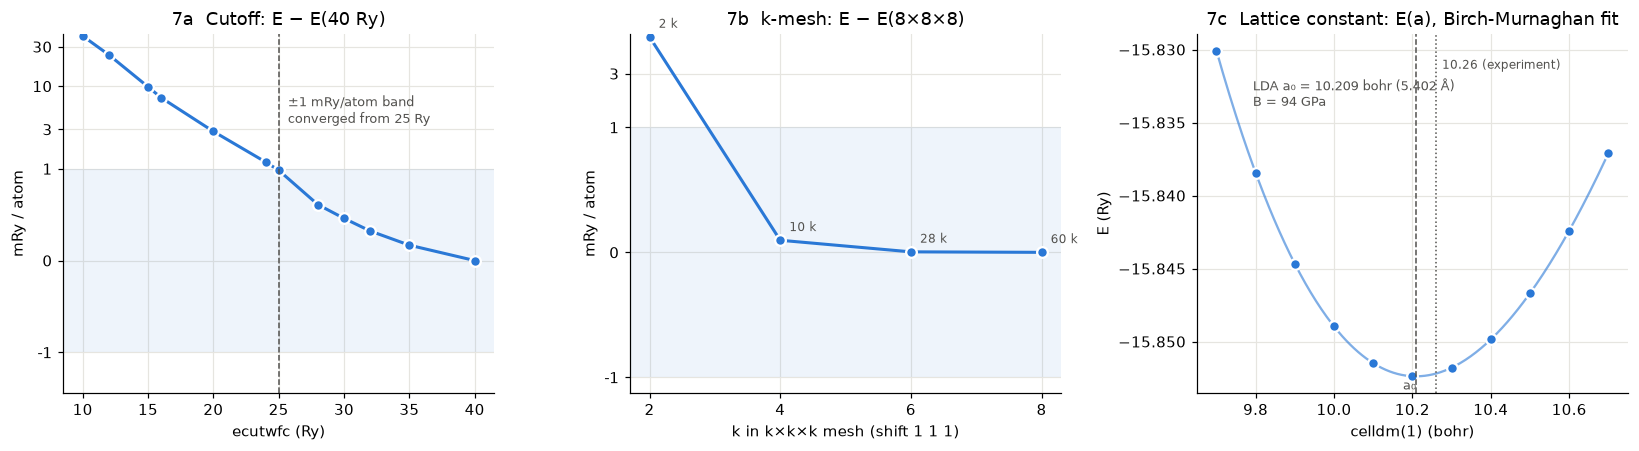

In [20]:
# Three separate panels (small multiples), one quantity each - no shared or dual axes
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), dpi=110)
style = dict(color="#2a78d6", lw=2, marker="o", ms=7, markeredgecolor="white", markeredgewidth=1.5)

ax = axs[0]
ax.plot(ecut_df["ecutwfc (Ry)"], ecut_df["E - E(40) (mRy/atom)"], **style)
ax.axhspan(-1, 1, color="#2a78d6", alpha=0.08, lw=0)
ax.axvline(ECUT_CONV, color="#52514e", lw=1, ls="--")
ax.annotate(f"±1 mRy/atom band\nconverged from {ECUT_CONV} Ry", (ECUT_CONV, 1), xytext=(6, 30),
            textcoords="offset points", fontsize=8.5, color="#52514e")
ax.set(title="7a  Cutoff: E − E(40 Ry)", xlabel="ecutwfc (Ry)", ylabel="mRy / atom")
ax.set_yscale("symlog", linthresh=1)

ax = axs[1]
ax.plot(KS, k_df["E - E(8) (mRy/atom)"], **style)
ax.axhspan(-1, 1, color="#2a78d6", alpha=0.08, lw=0)
for k, nk, d in zip(KS, k_df["irreducible k-points"], k_df["E - E(8) (mRy/atom)"]):
    ax.annotate(f"{nk} k", (k, d), xytext=(6, 6), textcoords="offset points", fontsize=8, color="#52514e")
ax.set(title="7b  k-mesh: E − E(8×8×8)", xlabel="k in k×k×k mesh (shift 1 1 1)", ylabel="mRy / atom")
ax.set_xticks(KS)
ax.set_yscale("symlog", linthresh=1)

ax = axs[2]
a_fine = np.linspace(ALATS.min(), ALATS.max(), 300)
e_fine = eos.func((a_fine * Bohr) ** 3 / 4, *eos.eos_parameters) / Ry
ax.plot(a_fine, e_fine, color="#2a78d6", lw=1.5, alpha=0.6)
ax.plot(alat_df["celldm(1) (bohr)"], alat_df["E (Ry)"], ls="", marker="o", ms=7, color="#2a78d6",
        markeredgecolor="white", markeredgewidth=1.5)
ax.axvline(A0_BOHR, color="#52514e", lw=1, ls="--")
ax.axvline(10.26, color="#52514e", lw=1, ls=":")
ax.annotate(f"LDA a₀ = {A0_BOHR:.3f} bohr ({A0_BOHR * Bohr:.3f} Å)\nB = {B_GPA:.0f} GPa", (A0_BOHR, e_fine.min()),
            xytext=(0.13, 0.80), textcoords="axes fraction", fontsize=8.5, color="#52514e")
ax.text(A0_BOHR, ax.get_ylim()[0], " a₀", fontsize=8.5, color="#52514e", va="bottom", ha="right")
ax.annotate("10.26 (experiment)", (10.26, e_fine.max()), xytext=(4, -12), textcoords="offset points",
            fontsize=8, color="#52514e")
ax.set(title="7c  Lattice constant: E(a), Birch-Murnaghan fit", xlabel="celldm(1) (bohr)", ylabel="E (Ry)")

from matplotlib.ticker import FixedLocator, FuncFormatter
for ax in axs[:2]:   # symlog: linear within ±1 mRy/atom, log beyond; plain-number tick labels
    ax.yaxis.set_major_locator(FixedLocator([-1, 0, 1, 3, 10, 30]))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
for ax in axs:
    ax.grid(True, color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## 8. Structure Optimzation 

In [21]:
OPT_INPUT = f'''&control
    calculation = 'vc-relax'
    prefix = 'silicon_opt'
    outdir = './tmp/'
    pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
    etot_conv_thr = 1e-5
    forc_conv_thr = 1e-4
/
&system
    ibrav=2, celldm(1) =14,
    nat=2, ntyp=1,
    ecutwfc=30
/
&electrons
    conv_thr=1e-8
/
&ions
/
&cell
    cell_dofree='ibrav'
/
ATOMIC_SPECIES
  Si  28.0855  Si.pz-vbc.UPF

ATOMIC_POSITIONS (alat)
  Si 0.00 0.00 0.00 0 0 0
  Si 0.25 0.25 0.25 0 0 0

K_POINTS (automatic)
   6 6 6 1 1 1
'''
OPT = ROOT / "runs" / "opt_silicon"
OPT.mkdir(parents=True, exist_ok=True)
(OPT / "pw.opt_silicon.in").write_text(OPT_INPUT)

499

In [22]:
t0 = time.time()
with open(OPT / "pw.opt_silicon.in") as fin, open(OPT / "pw.opt_silicon.out", "w") as fout:
    proc = subprocess.run([PW], stdin=fin, stdout=fout, stderr=subprocess.PIPE, cwd=OPT, text=True,
                          env={**os.environ, "OMP_NUM_THREADS": "1"})
elapsed = time.time() - t0
OUT = (OPT / "pw.opt_silicon.out").read_text()

check("pw.x exit code 0", proc.returncode == 0, f"code {proc.returncode} {proc.stderr[-300:]}")
check("JOB DONE", "JOB DONE" in OUT, f"{elapsed:.1f} s")
check("BFGS converged", "bfgs converged" in OUT)
print(re.search(r"Program PWSCF.*", OUT).group(0))

[PASS] pw.x exit code 0 - code 0 Note: The following floating-point exceptions are signalling: IEEE_DENORMAL

[PASS] JOB DONE - 18.3 s
[PASS] BFGS converged
Program PWSCF v.7.6 starts on  4Nov2026 at 23:42:41 


## 9. Density of States

In [23]:
DENS_INPUT = f'''&CONTROL
  calculation = 'scf',
  restart_mode = 'from_scratch',
  prefix = 'silicon',
  outdir = './tmp/'
  pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
  verbosity = 'high'
/

&SYSTEM
  ibrav = 2,
  celldm(1) = 10.2076,
  nat = 2,
  ntyp = 1,
  ecutwfc = 50,
  nbnd = 8,
  occupations='tetrahedra'
/

&ELECTRONS
  conv_thr = 1e-8,
  mixing_beta = 0.6
/

ATOMIC_SPECIES
  Si 28.086 Si.pz-vbc.UPF

ATOMIC_POSITIONS (alat)
  Si 0.0 0.0 0.0
  Si 0.25 0.25 0.25

K_POINTS (automatic)
  12 12 12 0 0 0
'''
DENS = ROOT / "runs" / "dens_silicon"
DENS.mkdir(parents=True, exist_ok=True)
(DENS / "pw.scf.dens_silicon.in").write_text(DENS_INPUT)

508

In [24]:
t0 = time.time()
with open(DENS / "pw.scf.dens_silicon.in") as fin, open(DENS / "pw.scf.dens_silicon.out", "w") as fout:
    proc = subprocess.run([PW], stdin=fin, stdout=fout, stderr=subprocess.PIPE, cwd=OPT, text=True,
                          env={**os.environ, "OMP_NUM_THREADS": "1"})
elapsed = time.time() - t0
OUT = (DENS / "pw.scf.dens_silicon.out").read_text()

check("pw.x exit code 0", proc.returncode == 0, f"code {proc.returncode} {proc.stderr[-300:]}")
check("JOB DONE", "JOB DONE" in OUT, f"{elapsed:.1f} s")
check("BFGS converged", "bfgs converged" in OUT)
print(re.search(r"Program PWSCF.*", OUT).group(0))

[PASS] pw.x exit code 0 - code 0 
[PASS] JOB DONE - 6.1 s
[FAIL] BFGS converged
Program PWSCF v.7.6 starts on  4Nov2026 at 23:42:59 


In [25]:
&DOS
  prefix='silicon',
  outdir='./tmp/',
  fildos='si_dos.dat',
  emin=-9.0,
  emax=16.0


SyntaxError: invalid syntax (523399559.py, line 1)

In [ ]:
DENS_INPUT_NSCF = f'''&CONTROL
  calculation = 'nscf',
  restart_mode = 'from_scratch',
  prefix = 'silicon',
  outdir = './tmp/'
  pseudo_dir = '{PSEUDO_DIR.as_posix()}/'
  verbosity = 'high'
/

&SYSTEM
  ibrav = 2,
  celldm(1) = 10.2076,
  nat = 2,
  ntyp = 1,
  ecutwfc = 50,
  nbnd = 8,
  occupations='tetrahedra'
/

&ELECTRONS
  conv_thr = 1e-8,
  mixing_beta = 0.6
/

ATOMIC_SPECIES
  Si 28.086 Si.pz-vbc.UPF

ATOMIC_POSITIONS (alat)
  Si 0.0 0.0 0.0
  Si 0.25 0.25 0.25

K_POINTS (automatic)
  12 12 12 0 0 0
'''
DENS = ROOT / "runs" / "dens_silicon"
DENS.mkdir(parents=True, exist_ok=True)
(DENS / "pw.nscf.dens_silicon.in").write_text(DENS_INPUT)

In [ ]:
t0 = time.time()
with open(DENS / "pw.nscf.dens_silicon.in") as fin, open(DENS / "pw.nscf.dens_silicon.out", "w") as fout:
    proc = subprocess.run([PW], stdin=fin, stdout=fout, stderr=subprocess.PIPE, cwd=OPT, text=True,
                          env={**os.environ, "OMP_NUM_THREADS": "1"})
elapsed = time.time() - t0
OUT = (DENS / "pw.nscf.dens_silicon.out").read_text()

check("pw.x exit code 0", proc.returncode == 0, f"code {proc.returncode} {proc.stderr[-300:]}")
check("JOB DONE", "JOB DONE" in OUT, f"{elapsed:.1f} s")
check("BFGS converged", "bfgs converged" in OUT)
print(re.search(r"Program PWSCF.*", OUT).group(0))